In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
db=pd.read_csv("Diabetes.csv")

In [3]:
#Select features and target
X = db.drop("Outcome", axis=1)
y = db["Outcome"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome

Shape of X: (768, 8)
Shape of y: (768,)


In [4]:
#Invalid Values
invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[invalid_columns] = X[invalid_columns].replace(0, np.nan)

for column in invalid_columns:
    X[column] = X[column].fillna(X[column].median())

print("Missing values after preprocessing:")
print(X.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [5]:
#Divide the data into training and testing sets
#80% for training and 20% for testing, with stratification so both 
#sets maintain a similar proportion of diabetic and non-diabetic patients.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (614, 8)
Testing data shape: (154, 8)


In [6]:
#Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature standardization completed successfully.
Training data shape: (614, 8)
Testing data shape: (154, 8)


In [7]:
#Train the Logistic Regression model
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [8]:
#Apply 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1"]
)

print("Accuracy for each fold:")
print(cv_results["test_accuracy"])

print("\nF1-score for each fold:")
print(cv_results["test_f1"])

Accuracy for each fold:
[0.77235772 0.80487805 0.81300813 0.7804878  0.77868852]

F1-score for each fold:
[0.63157895 0.71428571 0.67605634 0.64935065 0.66666667]


In [9]:
#Calculate Mean and Standard Deviation
accuracy_mean = cv_results["test_accuracy"].mean()
accuracy_std = cv_results["test_accuracy"].std()

f1_mean = cv_results["test_f1"].mean()
f1_std = cv_results["test_f1"].std()

print(f"Mean Accuracy: {accuracy_mean:.4f}")
print(f"Standard Deviation of Accuracy: {accuracy_std:.4f}")

print(f"\nMean F1-score: {f1_mean:.4f}")
print(f"Standard Deviation of F1-score: {f1_std:.4f}")

Mean Accuracy: 0.7899
Standard Deviation of Accuracy: 0.0160

Mean F1-score: 0.6676
Standard Deviation of F1-score: 0.0279


In [10]:
#Calculate Brier Score
# Get predicted probabilities on the test set
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate Brier Score
brier = brier_score_loss(y_test, y_prob)

print(f"Brier Score: {brier:.4f}")

Brier Score: 0.1692


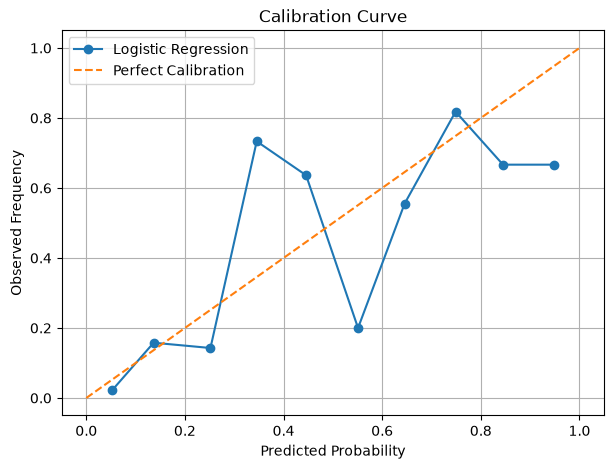

In [11]:
#Generate the Calibration Curve
prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Perfect Calibration"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Frequency")
plt.title("Calibration Curve")
plt.legend()
plt.grid()

plt.show()

In [12]:
print("Calibration values:")

for predicted, observed in zip(prob_pred, prob_true):
    print(f"Predicted = {predicted:.2f}, Observed = {observed:.2f}")

Calibration values:
Predicted = 0.05, Observed = 0.02
Predicted = 0.14, Observed = 0.16
Predicted = 0.25, Observed = 0.14
Predicted = 0.35, Observed = 0.73
Predicted = 0.45, Observed = 0.64
Predicted = 0.55, Observed = 0.20
Predicted = 0.65, Observed = 0.56
Predicted = 0.75, Observed = 0.82
Predicted = 0.84, Observed = 0.67
Predicted = 0.95, Observed = 0.67


In [13]:
#Import SHAP
import shap

print("SHAP imported successfully.")

ModuleNotFoundError: No module named 'shap'

In [14]:
!pip install shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [15]:
import shap

print("SHAP imported successfully.")

ModuleNotFoundError: No module named 'shap'

In [16]:
import sys
!{sys.executable} -m pip install shap

  Using cached shap-0.52.0-cp312-abi3-win_amd64.whl.metadata (26 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.52.0-cp312-abi3-win_amd64.whl (499 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/43.0 MB 9.1 MB/s eta 0:00:05
   --- ------------------------------------ 3.7/43.0 MB 9.0 MB/s eta 0:00:05
   ----- ---------------------------------- 5.5/43.0 MB 8.7 MB/s eta 0:00:05
   ------ --------------------------------- 7.1/43.0 MB 8.5 MB/s eta 0:00:05
   -------- ------------------------------- 8.7/43.0 MB 8.3 MB/s eta 0:00:05
   --------- ------------------------------ 10.5/43.0 MB 8.2 MB/s eta 0:00:04
   ----------- ---------------------------- 12.1/43.0 MB 8.0 MB/s eta 0:00:04
   ------------ --------------------------- 13.6/43.0 MB 8.0 MB/s eta 0:00:04
   -------------- ------------------------- 15.2/43.0 MB 7.9 MB/s eta

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:
import shap

print("SHAP imported successfully.")

C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP imported successfully.


In [18]:
#Create the SHAP Explainer
explainer = shap.LinearExplainer(model, X_train_scaled)

shap_values = explainer(X_test_scaled)

print("SHAP explanation generated successfully.")

Background dataset has 614 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=614 when initializing the masker.


SHAP explanation generated successfully.


In [19]:
#Find the Most Important Features
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean |SHAP value|": np.abs(shap_values.values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    "Mean |SHAP value|",
    ascending=False
)

print("Feature Importance based on SHAP:")
print(feature_importance.round(4))

Feature Importance based on SHAP:
                    Feature  Mean |SHAP value|
1                   Glucose             0.8042
4                   Insulin             0.5011
5                       BMI             0.3849
0               Pregnancies             0.3049
3             SkinThickness             0.2083
7                       Age             0.1366
6  DiabetesPedigreeFunction             0.1303
2             BloodPressure             0.0030


In [20]:
#Individual Prediction
patient_index = 0

print("Actual Outcome:", y_test.iloc[patient_index])
print("Predicted Outcome:", model.predict(X_test_scaled[patient_index].reshape(1, -1))[0])
print("Predicted Probability of Diabetes:",
      model.predict_proba(X_test_scaled[patient_index].reshape(1, -1))[0][1])

print("\nSHAP values for the patient:")

for feature, value in zip(X.columns, shap_values.values[patient_index]):
    print(f"{feature}: {value:.4f}")

Actual Outcome: 0
Predicted Outcome: 0
Predicted Probability of Diabetes: 0.47739550513864853

SHAP values for the patient:
Pregnancies: 0.2821
Glucose: 1.2270
BloodPressure: 0.0029
SkinThickness: -0.0562
Insulin: -0.2714
BMI: -0.3506
DiabetesPedigreeFunction: -0.0921
Age: 0.0649


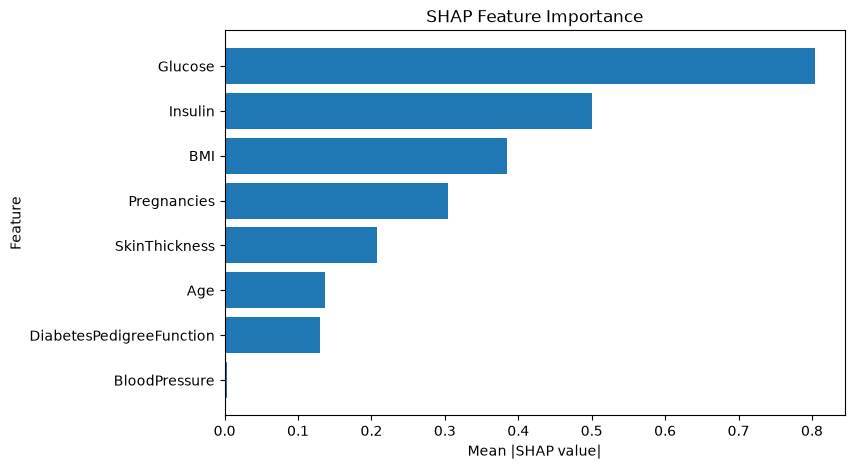

In [21]:
#SHAP Feature Importance Plot
plt.figure(figsize=(8, 5))

shap_importance = feature_importance.sort_values(
    "Mean |SHAP value|"
)

plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean |SHAP value|"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance")

plt.show()